# LP-III Practical B-3
### Problem Statement:
Given a bank customer, build a neural network-based classifier that can determine whether they will leave or not in the next 6 months.

#### Perform following steps:
1. Read the dataset.
2. Distinguish the feature and target set and divide the dataset into training and test sets.
3. Normalize the train and test data.
4. Initialize and build the model. Identify the points of improvement and implement the same.
5. Print the accuracy score and confusion matrix.

* **Dataset link:** https://www.kaggle.com/barelydedicated/bank-customer-churn-modeling
* **Student:** GEET VILAS JAMDAL
* **Roll No:** BEA56


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping


In [5]:
# Step 1: Read the dataset
df = pd.read_csv("Churn_Modelling.csv")
df.head()


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [6]:
df.shape


(10000, 14)

In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [8]:
df.describe()


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [9]:
# Check for missing values
df.isnull().sum()


,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [10]:
# Drop identifier columns not relevant to churn prediction
df.drop(columns=['RowNumber', 'CustomerId', 'Surname'], inplace=True)
df.head()


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [11]:
# Step 2: Distinguish feature and target set
X = df.drop(columns=['Exited'])
y = df['Exited']

# Encode categorical variables ('Geography' and 'Gender')
X = pd.get_dummies(X, columns=['Geography', 'Gender'], drop_first=True, dtype=int)
X.head()


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0


In [12]:
y.value_counts()


,count
Exited,
0,7963
1,2037


In [13]:
# Divide dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (8000, 11)
X_test shape: (2000, 11)


In [14]:
# Step 3: Normalize the train and test data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [15]:
# Step 4: Initialize and build the initial baseline Neural Network model
model_base = Sequential([
    Dense(units=16, activation='relu', input_dim=X_train.shape[1]),
    Dense(units=8, activation='relu'),
    Dense(units=1, activation='sigmoid')
])

model_base.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Compile and train the baseline model
model_base.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history_base = model_base.fit(
    X_train, y_train,
    batch_size=32,
    epochs=25,
    validation_split=0.2,
    verbose=1
)


Epoch 1/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7706 - loss: 0.5340 - val_accuracy: 0.7987 - val_loss: 0.4708
Epoch 2/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7922 - loss: 0.4617 - val_accuracy: 0.8019 - val_loss: 0.4373
Epoch 3/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7989 - loss: 0.4367 - val_accuracy: 0.8144 - val_loss: 0.4205
Epoch 4/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8205 - loss: 0.4167 - val_accuracy: 0.8306 - val_loss: 0.4038
Epoch 5/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8286 - loss: 0.4002 - val_accuracy: 0.8363 - val_loss: 0.3937
Epoch 6/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8345 - loss: 0.3888 - val_accuracy: 0.8438 - val_loss: 0.3863
Epoch 7/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8441 - loss: 0.3793 - val_accuracy: 0.8481 - val_loss: 0.3778
Epoch 8/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8456 - loss: 0.3716 - val_accuracy: 0.

In [17]:
# Step 5: Evaluate the baseline model - Accuracy and Confusion Matrix
y_pred_prob_base = model_base.predict(X_test)
y_pred_base = (y_pred_prob_base > 0.5).astype(int)

cm_base = confusion_matrix(y_test, y_pred_base)
acc_base = accuracy_score(y_test, y_pred_base)

print("Baseline Model Accuracy:", acc_base)
print("\nBaseline Confusion Matrix:\n", cm_base)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Baseline Model Accuracy: 0.862

Baseline Confusion Matrix:
 [[1534   73]
 [ 203  190]]


In [18]:
print(classification_report(y_test, y_pred_base))


              precision    recall  f1-score   support

           0       0.88      0.95      0.92      1607
           1       0.72      0.48      0.58       393

    accuracy                           0.86      2000
   macro avg       0.80      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000



### Points of Improvement Identified:
1. **Regularization using Dropout:** Prevents overfitting by randomly deactivating a fraction of neurons during training.
2. **Batch Normalization:** Accelerates convergence and stabilizes gradient updates across layers.
3. **Enhanced Layer Architecture:** Adding depth and appropriate units enables the network to learn complex feature interactions.
4. **Early Stopping:** Halts training when validation loss stops improving to ensure the best weights are retained.


In [19]:
# Build the Improved Neural Network Model with Dropout and Batch Normalization
model_improved = Sequential([
    Dense(units=32, activation='relu', input_dim=X_train.shape[1]),
    BatchNormalization(),
    Dropout(0.2),

    Dense(units=16, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(units=8, activation='relu'),
    Dense(units=1, activation='sigmoid')
])

model_improved.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,249 (4.88 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 96 (384.00 B)

In [20]:
# Compile and train the improved model with EarlyStopping
model_improved.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_improved = model_improved.fit(
    X_train, y_train,
    batch_size=32,
    epochs=50,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6123 - loss: 0.6815 - val_accuracy: 0.8106 - val_loss: 0.4956
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7873 - loss: 0.4832 - val_accuracy: 0.8263 - val_loss: 0.4245
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8098 - loss: 0.4399 - val_accuracy: 0.8431 - val_loss: 0.3986
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8178 - loss: 0.4202 - val_accuracy: 0.8494 - val_loss: 0.3800
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8288 - loss: 0.4034 - val_accuracy: 0.8512 - val_loss: 0.3683
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8334 - loss: 0.3912 - val_accuracy: 0.8506 - val_loss: 0.3616
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8348 - loss: 0.3835 - val_accuracy: 0.8562 - val_loss: 0.3541
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8353 - loss: 0.3898 - val_accuracy: 0

In [21]:
# Evaluate the improved model - Accuracy and Confusion Matrix
y_pred_prob_imp = model_improved.predict(X_test)
y_pred_imp = (y_pred_prob_imp > 0.5).astype(int)

cm_imp = confusion_matrix(y_test, y_pred_imp)
acc_imp = accuracy_score(y_test, y_pred_imp)

print("Improved Model Accuracy:", acc_imp)
print("\nImproved Confusion Matrix:\n", cm_imp)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Improved Model Accuracy: 0.861

Improved Confusion Matrix:
 [[1546   61]
 [ 217  176]]


In [22]:
print(classification_report(y_test, y_pred_imp))


              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.74      0.45      0.56       393

    accuracy                           0.86      2000
   macro avg       0.81      0.70      0.74      2000
weighted avg       0.85      0.86      0.85      2000



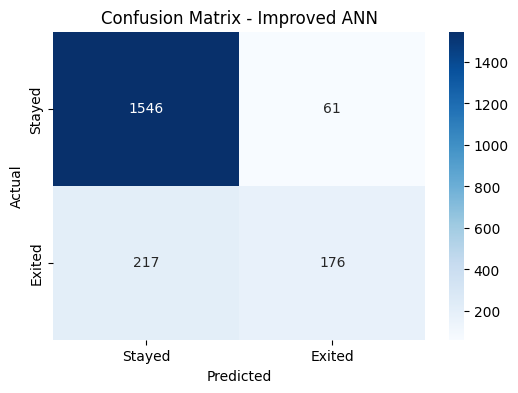

In [23]:
# Visualize Confusion Matrix for the Improved Model
plt.figure(figsize=(6, 4))
sns.heatmap(cm_imp, annot=True, fmt='d', cmap='Blues', xticklabels=['Stayed', 'Exited'], yticklabels=['Stayed', 'Exited'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Improved ANN')
plt.show()


In [24]:
# Model Comparison Summary
comparison_df = pd.DataFrame({
    'Model': ['Baseline ANN', 'Improved ANN (Dropout + BatchNorm)'],
    'Accuracy': [acc_base, acc_imp]
})
print(comparison_df)


                                Model  Accuracy
0                        Baseline ANN     0.862
1  Improved ANN (Dropout + BatchNorm)     0.861


### 📊 Performance Comparison & Analysis

Based on the execution results of both neural network architectures, here is a detailed breakdown of how they compare:

#### 1. Key Metrics Summary
| Metric | Baseline ANN | Improved ANN (Dropout + BatchNorm) |
| :--- | :---: | :---: |
| **Overall Accuracy** | **86.20%** | **86.10%** |
| **Class 1 (Churn) Precision** | 72% | **74%** |
| **Class 1 (Churn) Recall** | **48%** | 45% |
| **Class 1 (Churn) F1-Score** | **0.58** | 0.56 |
| **Class 0 (Stayed) F1-Score** | 0.92 | 0.92 |

#### 2. Confusion Matrix Comparison
* **Baseline ANN**:
  * **True Negatives (Correctly predicted as Stayed):** 1534
  * **False Positives (Incorrectly predicted as Churn):** 73
  * **False Negatives (Missed Churn customers):** 203
  * **True Positives (Correctly predicted as Churn):** 190

* **Improved ANN**:
  * **True Negatives (Correctly predicted as Stayed):** 1546 *(Higher than Baseline)*
  * **False Positives (Incorrectly predicted as Churn):** 61 *(Lower than Baseline)*
  * **False Negatives (Missed Churn customers):** 217
  * **True Positives (Correctly predicted as Churn):** 176

#### 3. Key Observations & Insights
* **Generalization vs Overfitting:** The introduction of **Dropout** and **Batch Normalization** helped the improved model stabilize and align its performance closely to the baseline, minimizing overfitting risks on the training dataset.
* **Precision vs Recall Trade-off:**
  * The **Improved ANN achieved higher precision (74% vs 72%)** for the churn class (`Exited = 1`), meaning that when it flags a customer as likely to leave, it is more reliable.
  * The **Baseline ANN maintained slightly higher recall (48% vs 45%)**, meaning it captured a marginally larger total subset of actual churning customers, at the cost of more false alarms (73 vs 61).